In [ ]:
# 2024/10/20
# Ziming Xu, Univeristy of Alberta
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import Callback, ModelCheckpoint
import numpy as np
import matplotlib.pyplot as plt
import pickle

## Component1: Proxy Model

In [ ]:
x_data_scaled = pickle.load(open('processed data/proxy_x_scaled.pkl', 'rb'))
y_data_scaled = pickle.load(open('processed data/proxy_y_scaled.pkl', 'rb'))

In [ ]:
# ✅ Sanity check
assert x_data_scaled.shape[0] == y_data_scaled.shape[0], "Batch sizes must match!"

# Create a random permutation of batch indices
np.random.seed(66)
perm = np.random.permutation(x_data_scaled.shape[0])

# Apply the same shuffle to both arrays
x_data_shuffled = x_data_scaled[perm]
y_data_shuffled = y_data_scaled[perm]

# ✅ Split
split_ratio = 0.99
x_train = x_data_shuffled[:int(x_data_shuffled.shape[0]*split_ratio),:,:]
x_test = x_data_shuffled[int(x_data_shuffled.shape[0]*split_ratio):,:,:]
y_train = y_data_shuffled[:int(x_data_shuffled.shape[0]*split_ratio),:,:]
y_test = y_data_shuffled[int(x_data_shuffled.shape[0]*split_ratio):,:,:]

# ✅ Print final shapes
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")

x_train shape: (3876, 73, 8)
y_train shape: (3876, 73, 1)
x_test shape: (40, 73, 8)
y_test shape: (40, 73, 1)


In [ ]:
from tensorflow.keras.layers import Layer
from tensorflow.keras.utils import register_keras_serializable

@register_keras_serializable()
class SelfAttention(Layer):
    def __init__(self, units=128, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.query_dense = keras.layers.Dense(units)
        self.key_dense = keras.layers.Dense(units)
        self.value_dense = keras.layers.Dense(units)
        self.softmax = keras.layers.Softmax(axis=-1)

    def build(self, input_shape):
        # Ensure sub-layers are built with the correct input shape
        self.query_dense.build(input_shape)
        self.key_dense.build(input_shape)
        self.value_dense.build(input_shape)
        super().build(input_shape)

    def call(self, inputs):
        query = self.query_dense(inputs)
        key = self.key_dense(inputs)
        value = self.value_dense(inputs)

        # Transpose key for dot product
        key = tf.transpose(key, perm=[0, 2, 1])
        attention_scores = tf.matmul(query, key) / tf.math.sqrt(tf.cast(self.units, tf.float32))
        attention_weights = self.softmax(attention_scores)
        output = tf.matmul(attention_weights, value)
        return output

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
# build a GRU model for regression task

# Input 1: static input
proxy_input = keras.Input(shape=(x_data_scaled.shape[1], x_data_scaled.shape[2]), name='static_input')

# GRU + Dropout
x = layers.GRU(128, return_sequences=True)(proxy_input)
x = layers.Dropout(0.1)(x)

# Optional: Self-attention layer (define this if not done yet)
x = SelfAttention()(x)  # <-- include if you have a working custom attention layer

x = layers.GRU(128, return_sequences=True)(x)
x = layers.Dropout(0.1)(x)

# Feed-forward layers
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(64, activation='relu')(x)
output = layers.Dense(1, activation='linear')(x)

# Build model
model = keras.Model(inputs= proxy_input , outputs=output)

# Compile
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model.compile(loss='mse', optimizer=optimizer)

# Summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ static_input (InputLayer)       │ (None, 73, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 73, 128)        │        52,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 73, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ self_attention (SelfAttention)  │ (None, 73, 128)        │        49,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 73, 128)        │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 73, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 73, 64)         │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 73, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 73, 64)         │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 73, 1)          │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 214,081 (836.25 KB)

 Trainable params: 214,081 (836.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: loss = {logs['loss']:.5f}, val_loss = {logs.get('val_loss', 0):.5f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: loss = {logs['loss']:.5f}, val_loss = {logs.get('val_loss', 0):.5f}")

# Automatically save the model with the lowest val_loss
checkpoint_cb = ModelCheckpoint(
    filepath='saved model/proxy_best.keras',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=False,
    verbose=0  # set to 1 to print a message when saving
)

model.fit(x_train, y_train, epochs=500, batch_size=256, validation_split=0.05, verbose=0, callbacks=[EveryNVerbose(n=10), checkpoint_cb])

Epoch 1: loss = 0.73428, val_loss = 0.66354
Epoch 10: loss = 0.08022, val_loss = 0.03956
Epoch 20: loss = 0.01688, val_loss = 0.00907
Epoch 30: loss = 0.01220, val_loss = 0.00807
Epoch 40: loss = 0.00907, val_loss = 0.01707
Epoch 50: loss = 0.00803, val_loss = 0.01583
Epoch 60: loss = 0.00675, val_loss = 0.01666
Epoch 70: loss = 0.00548, val_loss = 0.01277
Epoch 80: loss = 0.00469, val_loss = 0.01370
Epoch 90: loss = 0.00453, val_loss = 0.01466
Epoch 100: loss = 0.00391, val_loss = 0.01410
Epoch 110: loss = 0.00389, val_loss = 0.01536
Epoch 120: loss = 0.00333, val_loss = 0.01425
Epoch 130: loss = 0.00324, val_loss = 0.01515
Epoch 140: loss = 0.00311, val_loss = 0.01639
Epoch 150: loss = 0.00286, val_loss = 0.01496
Epoch 160: loss = 0.00250, val_loss = 0.01685
Epoch 170: loss = 0.00259, val_loss = 0.01490
Epoch 180: loss = 0.00268, val_loss = 0.01510
Epoch 190: loss = 0.00309, val_loss = 0.01360
Epoch 200: loss = 0.00232, val_loss = 0.01464
Epoch 210: loss = 0.00211, val_loss = 0.01684

### Proxy Prediction

In [ ]:
proxy = keras.models.load_model('model path', custom_objects={'SelfAttention': SelfAttention})

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step 


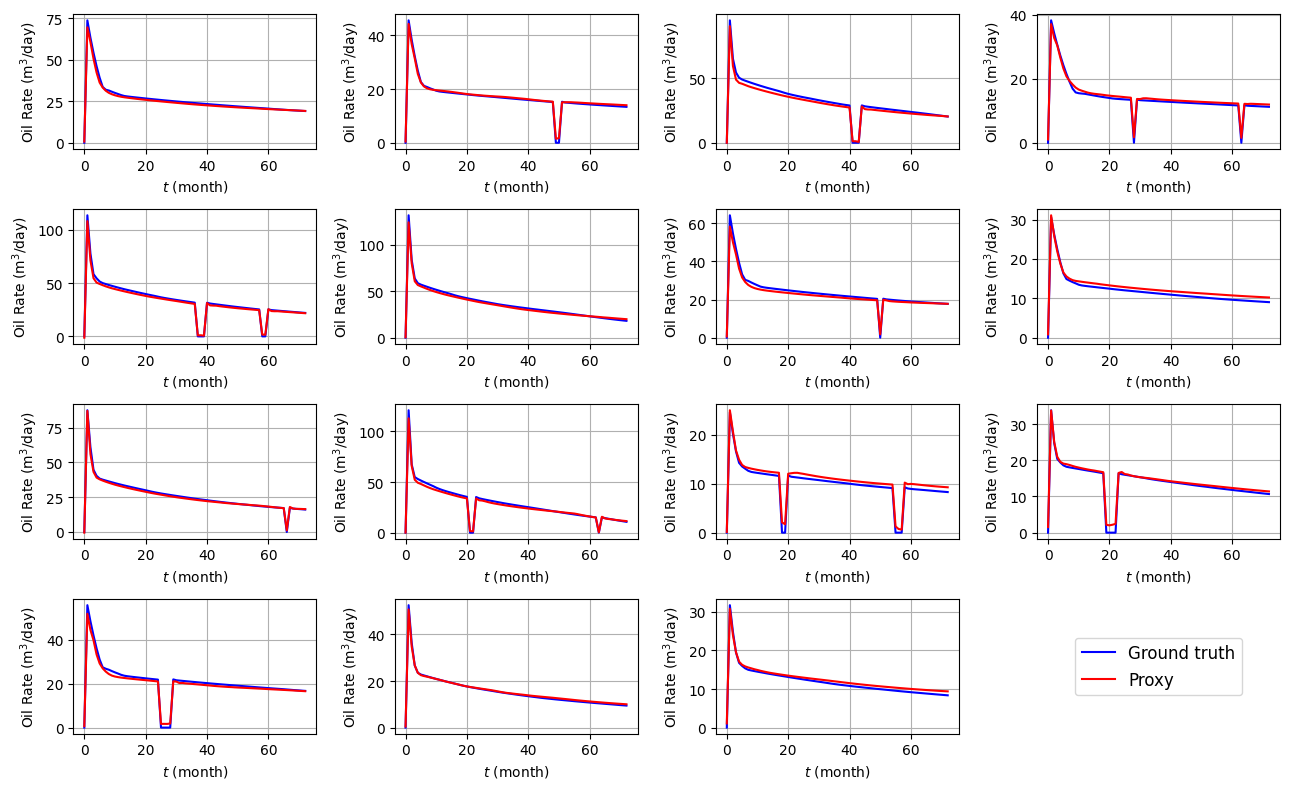

In [ ]:
y_scaler = pickle.load(open('processed data/y_scaler.pkl', 'rb'))

y_pred = proxy.predict(x_test)

original_shape = y_pred.shape
y_pred_flat = y_pred.reshape(-1,1)
y_test_flat = y_test.reshape(-1,1)

y_pred_inversed = y_scaler.inverse_transform(y_pred_flat).reshape(original_shape)
y_test_inversed = y_scaler.inverse_transform(y_test_flat).reshape(original_shape)

fig, ax = plt.subplots(4, 4, figsize=(13, 8))
ax = ax.flatten()

for i in range(15):  # Only plot 15 subplots (0 to 14)
    plot_idx = i
    ax[i].plot(y_test_inversed[plot_idx, :, 0], label='Ground truth', color='blue')
    ax[i].plot(y_pred_inversed[plot_idx, :, 0], label='Proxy', color='red')
    ax[i].set_ylabel('Oil Rate (m$^3$/day)', fontsize=10)
    ax[i].set_xlabel('$t$ (month)', fontsize=10)
    ax[i].grid(True)

# Use the 16th subplot for a legend only
ax[15].axis('off')
line1, = ax[15].plot([], [], label='Ground truth', color='blue')
line2, = ax[15].plot([], [], label='Proxy', color='red')
ax[15].legend(handles=[line1, line2], loc='center', fontsize=12)

plt.tight_layout()
plt.show()

## Component2: VAE

In [ ]:
vae_data_scaled = pickle.load(open('processed data/vae_x_scaled.pkl', 'rb'))
vae_scaler = pickle.load(open('processed data/vae_scaler.pkl', 'rb'))

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
print(vae_data_scaled[:,0].min())
print(vae_data_scaled[:,0].max())

print(vae_data_scaled[:,1].min())
print(vae_data_scaled[:,1].max())

print(vae_data_scaled[:,2].min())
print(vae_data_scaled[:,2].max())

-1.0208597081759845
0.9619905399175182
-1.0111560861154616
1.010908139479965
-1.0032624313227438
1.000132990293288


In [ ]:
vae_data_train = vae_data_scaled[:int(vae_data_scaled.shape[0]*0.98),:]
vae_data_test = vae_data_scaled[int(vae_data_scaled.shape[0]*0.98):,:]
print(f"vae_data_train shape: {vae_data_train.shape}")
print(f"vae_data_test shape: {vae_data_test.shape}")

vae_data_train shape: (3837, 3)
vae_data_test shape: (79, 3)


In [ ]:
poro_range = (0.1019, 0.1287)
sw_range = (0.2131, 0.4678)
perm_range = (13.3013, 28.4507)
# Sample uniformly for each parameter
n_samples = 5000
poro_samples = np.random.uniform(*poro_range, size=(n_samples, 1))
sw_samples = np.random.uniform(*sw_range, size=(n_samples, 1))
perm_samples = np.random.uniform(*perm_range, size=(n_samples, 1))

# Concatenate into shape (5000, 3)
sample_array = np.hstack([poro_samples, sw_samples, perm_samples])
vae_data_scaled = vae_scaler.transform(sample_array)
# Check shape
print("Sample shape:", sample_array.shape)
print("Scaled shape:", vae_data_scaled.shape)
vae_data_train = vae_data_scaled[:int(vae_data_scaled.shape[0]*0.98),:]
vae_data_test = vae_data_scaled[int(vae_data_scaled.shape[0]*0.98):,:]
print(f"vae_data_train shape: {vae_data_train.shape}")
print(f"vae_data_test shape: {vae_data_test.shape}")

Sample shape: (5000, 3)
Scaled shape: (5000, 3)
vae_data_train shape: (4900, 3)
vae_data_test shape: (100, 3)


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


In [ ]:
class Sampling(keras.layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [ ]:
latent_dim = 32

# VAE_Encoder
encoder_input = keras.layers.Input(shape=(vae_data_scaled.shape[1],))

VAE_en1 = keras.layers.Dense(64, activation = 'relu')(encoder_input)
VAE_en1 = keras.layers.Dropout(0.2)(VAE_en1)
VAE_en2 = keras.layers.Dense(64, activation = 'relu')(VAE_en1)
VAE_en2 = keras.layers.Dropout(0.2)(VAE_en2)

x = keras.layers.Flatten()(VAE_en2)
z_mean = keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = keras.layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

# Define the model
VAE_encoder = keras.Model([encoder_input], [z_mean, z_log_var, z], name="VAE_encoder")
VAE_encoder.summary()

Model: "VAE_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 64)        │      4,160 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 64)        │          0 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      2,080 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      2,080 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 32)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,576 (33.50 KB)

 Trainable params: 8,576 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# VAE_Decoder
decoder_input = keras.Input(shape=(latent_dim,),name='latent_input')

VAE_de1 = keras.layers.Dense(64, activation = 'relu')(decoder_input)
VAE_de1 = keras.layers.Dropout(0.2)(VAE_de1)
VAE_de2 = keras.layers.Dense(64, activation = 'relu')(VAE_de1)
VAE_de2 = keras.layers.Dropout(0.2)(VAE_de2)
VAE_de_dense1 = keras.layers.Dense(64, activation='tanh')(VAE_de2)
VAE_de_output = keras.layers.Dense(vae_data_scaled.shape[1], activation = 'linear')(VAE_de_dense1)

VAE_decoder = keras.Model([decoder_input], VAE_de_output, name="VAE_decoder")
VAE_decoder.summary()

Model: "VAE_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,627 (41.51 KB)

 Trainable params: 10,627 (41.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#%% Define VAE
class Build_VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.gamma = 5000 # add weight to the reonstruction loss
        self.encoder = VAE_encoder
        self.decoder = VAE_decoder
        self.encoder_loss_tracker = keras.metrics.Mean(name="encoder_loss")
        self.recons_loss_tracker = keras.metrics.Mean(name="recons_loss")

        self.optimizer = tf.keras.optimizers.Adam(learning_rate = 0.0001)

    @property
    def metrics(self):
        return [
            self.encoder_loss_tracker,
            self.recons_loss_tracker]

    def train_step(self, data):
        en_features = data[0][0]

        # VAE
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder([en_features])

            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))

            reconstruction = self.decoder([z])
            reconstruction_loss = tf.reduce_mean(tf.keras.losses.MeanSquaredError()(en_features, reconstruction))
            encoder_loss = kl_loss+reconstruction_loss*self.gamma

        grads = tape.gradient(encoder_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.encoder_loss_tracker.update_state(kl_loss)
        self.recons_loss_tracker.update_state(reconstruction_loss)

        return {
            "kl": self.encoder_loss_tracker.result(),
            "recons": self.recons_loss_tracker.result()}

In [ ]:
vae = Build_VAE(VAE_encoder, VAE_decoder)
vae.compile(tf.keras.optimizers.Adam())

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl']:.9f}, Reconstruction loss = {logs['recons']:.5f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl']:.9f}, Reconstruction loss = {logs['recons']:.5f}")


# Automatically save the encoder and the decoder
class SaveEncoderDecoder(Callback):
    def __init__(self, encoder_path, decoder_path, monitor='recons', save_best_only=True):
        super().__init__()
        self.encoder_path = encoder_path
        self.decoder_path = decoder_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')  # initialize as very bad (infinite loss)

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: Metric '{self.monitor}' not found in logs.")
            return

        # Save if either not save_best_only or new best
        if not self.save_best_only or current < self.best:
            self.best = current
            print(f"Saving encoder and decoder at epoch {epoch + 1} with {self.monitor}: {current:.6f}")
            self.model.encoder.save(self.encoder_path)
            self.model.decoder.save(self.decoder_path)

save_cb = SaveEncoderDecoder(
    encoder_path='your path',
    decoder_path='your path',
    monitor='recons',
    save_best_only=True
)

vae.fit([vae_data_train],
        epochs=2000, batch_size=512, verbose = 0, callbacks= [EveryNVerbose(n=50), save_cb])

In [ ]:
custom_objects = {'Sampling': Sampling}
encoder_model = tf.keras.models.load_model('saved model/vae_encoder_best.keras',custom_objects=custom_objects)
decoder_model = tf.keras.models.load_model('saved model/vae_decoder_best.keras')

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step 

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_5
Received: inputs=('Tensor(shape=(32, 3))',)
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_5
Received: inputs=('Tensor(shape=(None, 3))',)
  warnings.warn(msg)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: latent_input
Received: inputs=('Tensor(shape=(32, 32))',)
  warnings.warn(msg)


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: latent_input
Received: inputs=('Tensor(shape=(None, 32))',)
  warnings.warn(msg)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


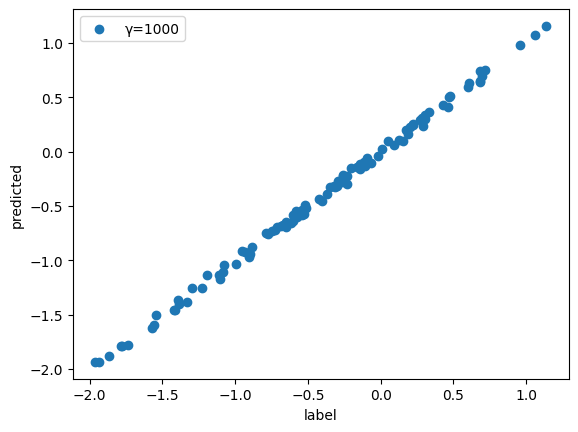

In [ ]:
en_pred = encoder_model.predict([vae_data_test])
de_pred = decoder_model.predict([en_pred[2]])

x_test_sum = np.sum(vae_data_test,axis=1)
de_pred_sum = np.sum(de_pred,axis=1)
plt.scatter(x_test_sum,de_pred_sum,label="γ=1000")
plt.xlabel('label')
plt.ylabel('predicted')
plt.legend()

## Component3: AssimNet

In [ ]:
# Load data
assim_x1_scaled = pickle.load(open('processed data/assim_x1_scaled.pkl', 'rb'))
assim_x2_scaled = pickle.load(open('processed data/assim_x2_scaled.pkl', 'rb'))
assim_y_scaled  = pickle.load(open('processed data/assim_y_scaled.pkl', 'rb'))
assim_x2 = pickle.load(open('processed data/assim_x2.pkl', 'rb'))

# ✅ Sanity check
assert assim_x1_scaled.shape[0] == assim_x2_scaled.shape[0] == assim_y_scaled.shape[0], "Sample size mismatch!"

# Shuffle consistently
np.random.seed(66)
perm = np.random.permutation(assim_x1_scaled.shape[0])

assim_x1_scaled = assim_x1_scaled[perm]
assim_x2_scaled = assim_x2_scaled[perm]
assim_y_scaled  = assim_y_scaled[perm]
assim_x2 = assim_x2[perm]

# ✅ Split
split_ratio = 0.9
split_index = int(assim_x1_scaled.shape[0] * split_ratio)

assim_x1_scaled_train = assim_x1_scaled[:split_index]
assim_x1_scaled_test  = assim_x1_scaled[split_index:]

assim_x2_scaled_train = assim_x2_scaled[:split_index]
assim_x2_scaled_test  = assim_x2_scaled[split_index:]

assim_x2_train = assim_x2[:split_index]
assim_x2_test  = assim_x2[split_index:]

assim_y_scaled_train  = assim_y_scaled[:split_index]
assim_y_scaled_test   = assim_y_scaled[split_index:]

# ✅ Print final shapes
print(f"assim_x1_scaled_train shape: {assim_x1_scaled_train.shape}")
print(f"assim_x2_scaled_train shape: {assim_x2_scaled_train.shape}")
print(f"assim_y_scaled_train  shape: {assim_y_scaled_train.shape}")
print(f"assim_x1_scaled_test  shape: {assim_x1_scaled_test.shape}")
print(f"assim_x2_scaled_test  shape: {assim_x2_scaled_test.shape}")
print(f"assim_y_scaled_test   shape: {assim_y_scaled_test.shape}")
print("====")
print(f"assim_x2_train shape: {assim_x2_train.shape}")
print(f"assim_x2_test  shape: {assim_x2_test.shape}")

assim_x1_scaled_train shape: (450, 5, 5)
assim_x2_scaled_train shape: (450, 73, 5)
assim_y_scaled_train  shape: (450, 73, 1)
assim_x1_scaled_test  shape: (50, 5, 5)
assim_x2_scaled_test  shape: (50, 73, 5)
assim_y_scaled_test   shape: (50, 73, 1)
====
assim_x2_train shape: (450, 73, 5)
assim_x2_test  shape: (50, 73, 5)


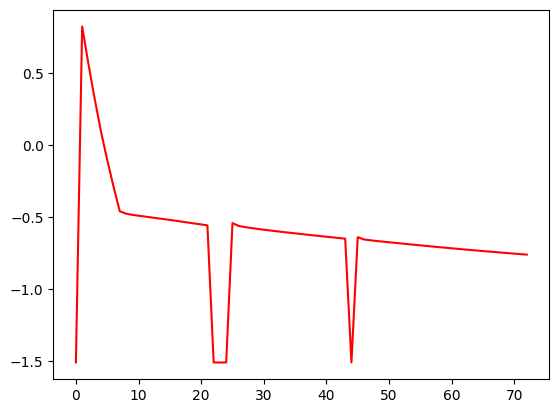

In [ ]:
for i in range(20,21):
    plt.plot(assim_y_scaled[i+20,:,:], 'r')

In [ ]:
## Define the Encoder
latent_dim = 32
encoder_input = keras.layers.Input(shape=(assim_x1_scaled.shape[1], assim_x1_scaled.shape[2]))  # (5, 5)

# Mean pooling over the "layer" axis (axis=1)
x_pooled = keras.layers.GlobalAveragePooling1D()(encoder_input)  # Now shape is (None, 5)

Assim_en1 = keras.layers.Dense(128, activation = 'relu')(x_pooled)
Assim_en1 = keras.layers.Dropout(0.2)(Assim_en1)
Assim_en2 = keras.layers.Dense(128, activation = 'relu')(Assim_en1)
Assim_en2 = keras.layers.Dropout(0.2)(Assim_en2)

x = keras.layers.Flatten()(Assim_en2)
z_mean = keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = keras.layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

# Define the model
Assim_encoder = keras.Model([encoder_input], [z_mean, z_log_var, z], name="Assim_encoder")
Assim_encoder.summary()

Model: "Assim_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 5, 5)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 5)         │          0 │ input_layer_1[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 128)       │        768 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 128)       │     16,512 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 128)       │          0 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 128)       │          0 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      4,128 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      4,128 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_1          │ (None, 32)        │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,536 (99.75 KB)

 Trainable params: 25,536 (99.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def assemble_simu_in(simu_in_recons, assim_x2):
    """
    Assemble simulation input by merging the decoder output (uncertain_cols)
    and field-known features (determined_cols + extra_cols), and reordering to match final_order.
    """
    # Input shape assertions:
    tf.debugging.assert_equal(tf.shape(simu_in_recons)[-1], 3, message="simu_in_recons must have 3 features")
    tf.debugging.assert_equal(tf.shape(assim_x2)[-1], 5, message="assim_x2 must have 5 features")

    batch_size = tf.shape(simu_in_recons)[0]

    # Repeat the decoder output over 73 timesteps
    simu_in_repeated = tf.repeat(tf.expand_dims(simu_in_recons, axis=1), repeats=73, axis=1)  # [batch_size, 73, 3]

    # Split assim_x2: [batch_size, 73, 5] → determined (4), extra (1)
    assim_x2_determined = assim_x2[:, :, :4]  # ['BHP','Pressure','Thickness','Top']
    assim_x2_extra = assim_x2[:, :, 4:]       # ['shut-in signal']

    # Build the mapping: column name → tensor
    feature_map = {}

    # uncertain_cols in the same order as in final_order
    uncertain_cols =['Por','Sw','Perm']

    for i, col in enumerate(uncertain_cols):
        feature_map[col] = simu_in_repeated[:, :, i]

    determined_cols = ['BHP','Pressure','Thickness','Top']
    for i, col in enumerate(determined_cols):
        feature_map[col] = assim_x2_determined[:, :, i]

    extra_cols = ['shut-in signal']
    for i, col in enumerate(extra_cols):
        feature_map[col] = assim_x2_extra[:, :, i]

    # Reconstruct input in the correct final order
    final_order = ['Por','Sw','Perm', 'BHP','Pressure','Thickness','Top','shut-in signal']

    reordered_features = [tf.expand_dims(feature_map[col], axis=-1) for col in final_order]
    simu_in_concat = tf.concat(reordered_features, axis=-1)  # [batch_size, 73, 8]

    return simu_in_concat

In [ ]:
def kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p):
    """KL divergence between two multivariate diagonal Gaussians"""
    var_q = tf.exp(logvar_q)
    var_p = tf.exp(logvar_p)

    kl = 0.5 * (
        tf.reduce_sum(logvar_p - logvar_q, axis=1)  # log |Σ_p| / |Σ_q|
        - tf.cast(tf.shape(mu_q)[1], tf.float32)    # -k
        + tf.reduce_sum(var_q / var_p, axis=1)       # Tr(Σ_p^-1 Σ_q)
        + tf.reduce_sum((mu_p - mu_q)**2 / var_p, axis=1)  # diff^T Σ_p^-1 diff
    )
    return tf.reduce_mean(kl)

class Build_AssimNet(keras.Model):
    def __init__(self, encoder, vae_encoder, decoder, proxy, **kwargs):
        super().__init__(**kwargs)
        self.lam = 0.001
        self.assim_encoder = encoder
        self.vae_encoder = vae_encoder
        self.decoder = decoder
        self.proxy = proxy
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")
        self.recons_loss_tracker = keras.metrics.Mean(name="recons_loss")
        self.assim_loss_tracker = keras.metrics.Mean(name="assim_loss")
        self.val_loss_tracker = keras.metrics.Mean(name="vaL_loss")
        self.optimizer = tf.keras.optimizers.Adam(learning_rate = 0.0001)

        # Set decoder and proxy as untrainable
        self.vae_encoder.trainable = False
        self.decoder.trainable = False
        self.proxy.trainable = False

    @property
    def metrics(self):
        return [self.kl_loss_tracker,
                self.recons_loss_tracker,
                self.assim_loss_tracker,
                self.val_loss_tracker]

    def train_step(self, data):
        assim_x1 = data[0][0]
        assim_x2 = data[0][1]
        assim_target = data[0][2]


        # VAE
        with tf.GradientTape() as tape:
            mu_q, logvar_q, z = self.assim_encoder([assim_x1])

            # KL loss
            recons4vae_encoder = self.decoder(z)
            mu_p, logvar_p, _ = self.vae_encoder(recons4vae_encoder)
            kl_loss = kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p)

            # Reconstruction loss
            simu_in_recons = self.decoder(z)
            simu_in_concate = assemble_simu_in(simu_in_recons,assim_x2)
            proxy_out = self.proxy(simu_in_concate)
            recons_loss = tf.keras.losses.MeanSquaredError()(proxy_out, assim_target)

            # Total loss
            assim_loss = recons_loss + kl_loss * self.lam


        grads = tape.gradient(assim_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.kl_loss_tracker.update_state(kl_loss)
        self.recons_loss_tracker.update_state(recons_loss)
        self.assim_loss_tracker.update_state(assim_loss)

        return {"kl_loss": self.kl_loss_tracker.result(),
                "recons_loss": self.recons_loss_tracker.result(),
                "assim_loss": self.assim_loss_tracker.result()}

    def test_step(self, data):
        assim_x1 = data[0][0]
        assim_x2 = data[0][1]
        assim_target = data[0][2]

        _, _, z = self.assim_encoder([assim_x1])

        simu_in_recons = self.decoder(z)
        simu_in_concate = assemble_simu_in(simu_in_recons,assim_x2)
        proxy_out = self.proxy(simu_in_concate)
        recons_loss = tf.keras.losses.MeanSquaredError()(proxy_out, assim_target)

        self.val_loss_tracker.update_state(recons_loss)

        return {
            "val_loss": self.val_loss_tracker.result(),
        }


In [ ]:
AssimNet = Build_AssimNet(Assim_encoder, encoder_model, decoder_model, proxy)
AssimNet.compile(tf.keras.optimizers.Adam())

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl_loss']:.9f}, Recons loss = {logs['recons_loss']:.5f}, Assim loss = {logs['assim_loss']:.5f}, val loss = {logs['val_val_loss']:.5f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: KL loss = {logs['kl_loss']:.9f}, Recons loss = {logs['recons_loss']:.5f}, Assim loss = {logs['assim_loss']:.5f}, val loss = {logs['val_val_loss']:.5f}")

# Automatically save the model with the lowest val_loss
class SaveEncoderDecoder(Callback):
    def __init__(self, encoder_path, monitor='recons_loss', save_best_only=True):
        super().__init__()
        self.encoder_path = encoder_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')  # initialize as very bad (infinite loss)

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: Metric '{self.monitor}' not found in logs.")
            return

        # Save if either not save_best_only or new best
        if not self.save_best_only or current < self.best:
            self.best = current
            print(f"Saving assimnet encoder at epoch {epoch + 1} with {self.monitor}: {current:.6f}")
            self.model.assim_encoder.save(self.encoder_path)

save_cb = SaveEncoderDecoder(
    encoder_path='saved model/assim_encoder_best.keras',
    monitor='val_val_loss',
    save_best_only=True
)

history = AssimNet.fit([assim_x1_scaled_train,assim_x2_scaled_train,assim_y_scaled_train],epochs=2000, batch_size=12, verbose = 0, validation_split = 0.1, callbacks=[EveryNVerbose(n=10), save_cb])

Text(0, 0.5, 'Loss')

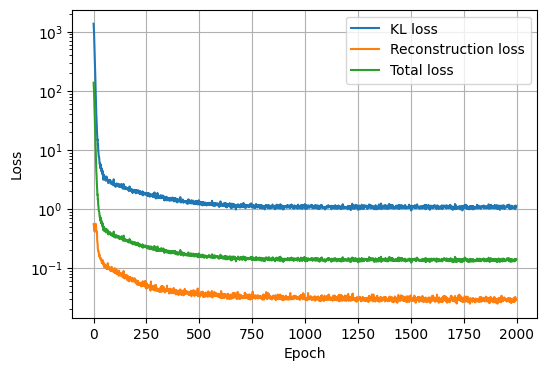

In [ ]:
import pickle
pickle.dump(history.history, open('assim_history2.pkl', 'wb'))
assim_history = pickle.load(open('assim_history2.pkl', 'rb'))
plt.figure(figsize=(6, 4))
plt.plot(assim_history['kl_loss'], label='KL loss')
plt.plot(assim_history['recons_loss'], label='Reconstruction loss')
plt.plot(assim_history['assim_loss'], label='Total loss')
plt.legend()
plt.grid()
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss')

In [ ]:
# AssimNet.encoder.save('saved model/assim_encoder.keras')
AssimNet_encoder = tf.keras.models.load_model('saved model/assim_encoder_best.keras',custom_objects=custom_objects)

In [ ]:
from sklearn.metrics import mean_squared_error

z_mean, z_log_var, z = AssimNet_encoder.predict(assim_x1_scaled_test)
simu_in_recons = decoder_model.predict(z)
simu_in_concate = assemble_simu_in(tf.cast(simu_in_recons, tf.float32),tf.cast(assim_x2_scaled_test, tf.float32))
proxy_out = proxy.predict(simu_in_concate)

rmse = np.sqrt(mean_squared_error(assim_y_scaled_test.reshape(-1), proxy_out.reshape(-1)))
print(f"RMSE: {rmse}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
RMSE: 0.19513647624181304


In [ ]:
import json
import numpy as np

# Predict from decoder
simu_in_recons = decoder_model.predict([z])

# Inverse transform
vae_scaler = pickle.load(open('processed data/vae_scaler.pkl', 'rb'))
simu_in_recons_inversed = vae_scaler.inverse_transform(simu_in_recons)  # shape: (N, 3)

# Prepare config dictionary
config = {"cases": []}
n_cases = simu_in_recons_inversed.shape[0]

for i in range(n_cases):
    case_data = {
        "Case_name": f"testing_well{str(i+1).zfill(2)}",
        "Por": float(simu_in_recons_inversed[i, 0]),
        "Sw": float(simu_in_recons_inversed[i, 1]),
        "Perm": float(simu_in_recons_inversed[i, 2]),
        "BHP": float(assim_x2_test[i, 0, 0]),
        "Pressure": float(assim_x2_test[i, 0, 1]),
        "Thickness": float(assim_x2_test[i, 0, 2]),
        "Top": float(assim_x2_test[i, 0, 3]),
        "shut-in signal": assim_x2_test[i, :, 4].astype(int).tolist()
    }
    config["cases"].append(case_data)

# Save as JSON
with open("saved results/testing_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("✅ Config saved to testing+config.json")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


✅ Config saved to testing+config.json


In [ ]:
inference_y_data  = pickle.load(open('saved results/inference_y_data.pkl', 'rb'))
label_inference_y_data  = pickle.load(open('saved results/label_inference_y_data.pkl', 'rb'))

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


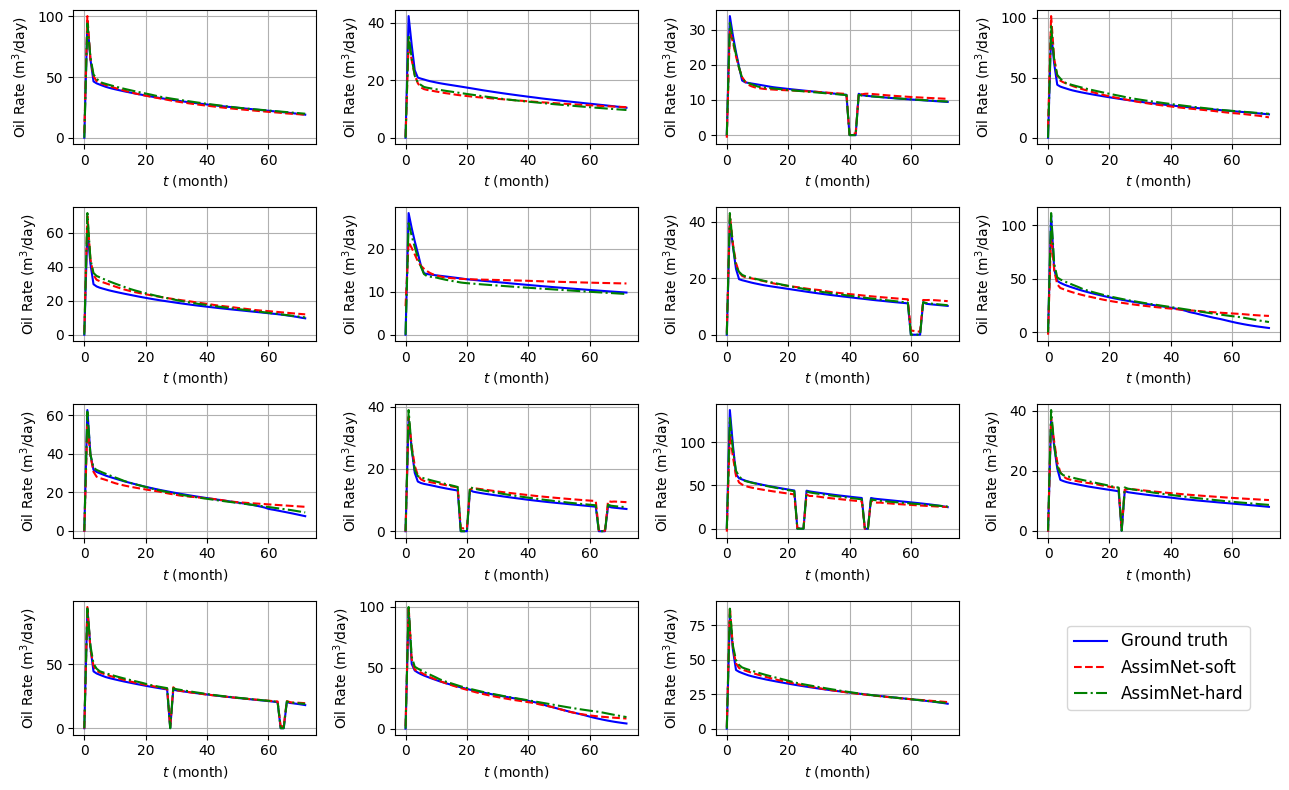

In [ ]:
## Import the scaler and reverse the output
output_scaler = pickle.load(open('processed data/y_scaler.pkl', 'rb'))
# Reshape to 2D for inverse_transform
assim_y_scaled_test_flat = assim_y_scaled_test.reshape(-1, 1)
proxy_out_flat = proxy_out.reshape(-1, 1)
original_shape = proxy_out.shape

# Apply inverse transform
assim_y_test_inversed = output_scaler.inverse_transform(assim_y_scaled_test_flat).reshape(original_shape)
proxy_out_inversed = output_scaler.inverse_transform(proxy_out_flat).reshape(original_shape)

fig, ax = plt.subplots(4, 4, figsize=(13, 8))
ax = ax.flatten()

for i in range(15):
    n_plot = i+25
    ax[i].plot(assim_y_test_inversed[n_plot, :, 0], label='Ground truth', color='blue', linestyle='-')
    ax[i].plot(proxy_out_inversed[n_plot, :, 0], label='AssimNet-soft', color='red', linestyle='--')
    ax[i].plot(inference_y_data[n_plot, :, 0], label='AssimNet-hard', color='green', linestyle='-.')

    ax[i].set_ylabel('Oil Rate (m$^3$/day)',fontsize=10)
    ax[i].set_xlabel('$t$ (month)',fontsize=10)
    ax[i].grid(True)

# 16th subplot: legend only
ax[15].axis('off')
l1, = ax[15].plot([], [], color='blue', linestyle='-', label='Ground truth')
l2, = ax[15].plot([], [], color='red', linestyle='--', label='AssimNet-soft')
l3, = ax[15].plot([], [], color='green', linestyle='-.', label='AssimNet-hard')
ax[15].legend(handles=[l1, l2, l3], loc='center', fontsize=12)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


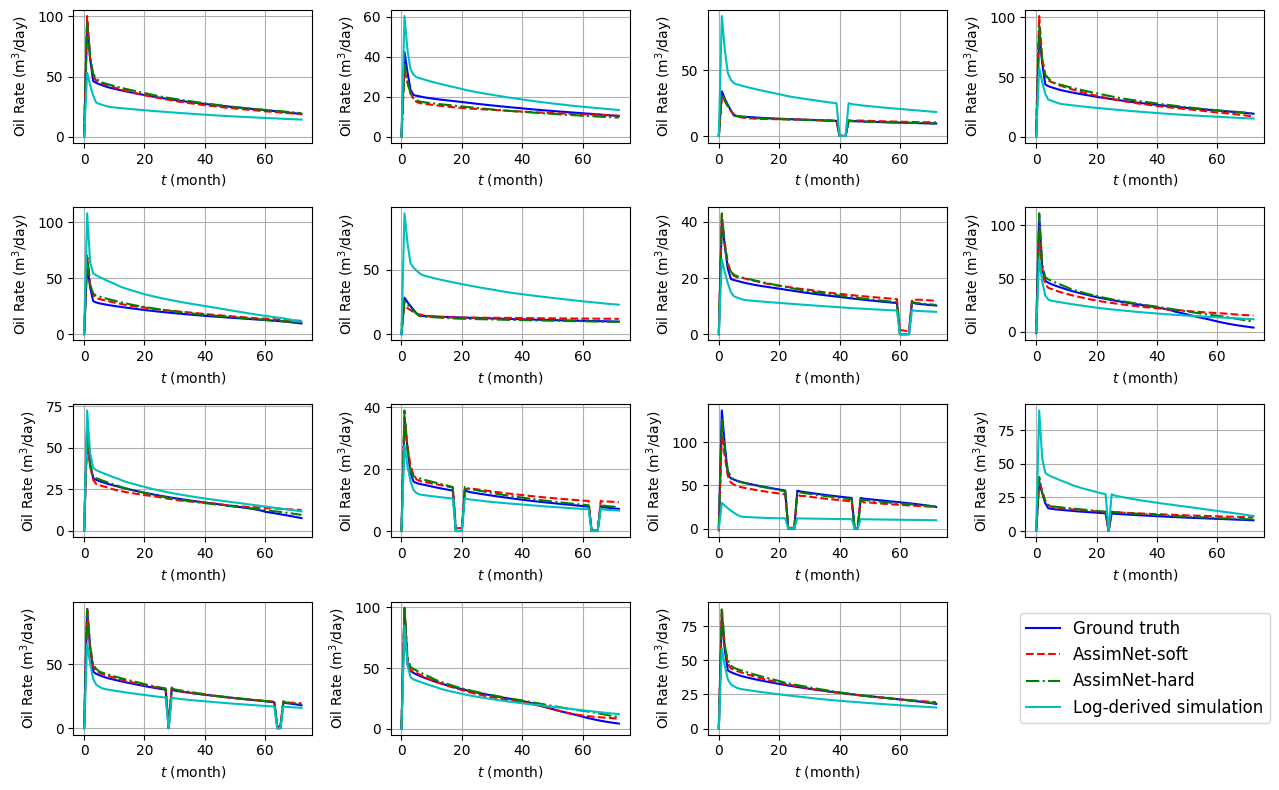

In [ ]:
## Import the scaler and reverse the output
output_scaler = pickle.load(open('processed data/y_scaler.pkl', 'rb'))
# Reshape to 2D for inverse_transform
assim_y_scaled_test_flat = assim_y_scaled_test.reshape(-1, 1)
proxy_out_flat = proxy_out.reshape(-1, 1)
original_shape = proxy_out.shape

# Apply inverse transform
assim_y_test_inversed = output_scaler.inverse_transform(assim_y_scaled_test_flat).reshape(original_shape)
proxy_out_inversed = output_scaler.inverse_transform(proxy_out_flat).reshape(original_shape)

fig, ax = plt.subplots(4, 4, figsize=(13, 8))
ax = ax.flatten()

for i in range(15):
    n_plot = i+25
    ax[i].plot(assim_y_test_inversed[n_plot, :, 0], label='Ground truth', color='blue', linestyle='-')
    ax[i].plot(proxy_out_inversed[n_plot, :, 0], label='AssimNet-soft', color='red', linestyle='--')
    ax[i].plot(inference_y_data[n_plot, :, 0], label='AssimNet-hard', color='green', linestyle='-.')
    ax[i].plot(label_inference_y_data[n_plot, :, 0], label='Log-derived simulation', color='c', linestyle='-')


    ax[i].set_ylabel('Oil Rate (m$^3$/day)',fontsize=10)
    ax[i].set_xlabel('$t$ (month)',fontsize=10)
    ax[i].grid(True)

# 16th subplot: legend only
ax[15].axis('off')
l1, = ax[15].plot([], [], color='blue', linestyle='-', label='Ground truth')
l2, = ax[15].plot([], [], color='red', linestyle='--', label='AssimNet-soft')
l3, = ax[15].plot([], [], color='green', linestyle='-.', label='AssimNet-hard')
l4, = ax[15].plot([], [], color='c', linestyle='-', label='Log-derived simulation')
ax[15].legend(handles=[l1, l2, l3, l4], loc='center', fontsize=12)

plt.tight_layout()
plt.show()

## Mutual Correlation and translation

**Proxy**
* poro_range = (0.1, 0.15)
* sw_range = (0.2,0.5)
* perm_range = (10, 30)

**Field**
* poro_range = (0.10192220646722594 0.12869771906806884)
* sw_range = (0.21312255638170552 0.46775860811297076)
* perm_range = (13.301332426907397 28.450601995302943)

In [ ]:
def compute_permeability(phi_eff):
    d = 0.00001 #m
    c = 10
    return ((phi_eff ** 3) * d ** 2) / (c * (1 - phi_eff) ** 2) * 1.01325e15

def cal_params_from_log(log_df):
    """
    Calculate effective porosity, water saturation, and permeability
    from well log data using GR, DPHI, NPHI, RHOB, ILD.

    Args:
        log_df (pd.DataFrame): Input DataFrame with logs:
            ['GR', 'DPHI', 'NPHI', 'RHOB', 'ILD']

    Returns:
        pd.DataFrame: With added columns:
            ['Effective_Porosity', 'Water_Saturation', 'Permeability']
    """
    # Constants
    rho_ma = 2.75  # Matrix density (g/cc)
    rho_f = 1    # Fluid density (g/cc)
    m = 1        # Cementation exponent
    n = 2.5        # Saturation exponent
    Rw = 0.12      # Formation water resistivity
    GR_clean = 45
    GR_shale = 120

    # Step 1: Total porosity from RHOB (convert to fraction)
    phi_RHOB = (rho_ma - log_df['RHOB']) / (rho_ma - rho_f)

    # Step 2: Porosity from DPHI & NPHI (assumed in fraction)
    phi_DN = np.sqrt(((log_df['DPHI']/100)**2 + (log_df['NPHI']/100)**2) / 2)

    # Step 3: Average porosity
    phi_avg = (phi_RHOB+ phi_DN)/2

    # Step 4: Shale volume from GR
    Vsh = (log_df['GR'] - GR_clean) / (GR_shale - GR_clean)
    Vsh = Vsh.clip(0, 1)

    # Step 5: Effective porosity
    phi_eff = phi_avg * (1 - Vsh)

    # Step 6: Water saturation (Archie's Equation)
    Rt = log_df['ILD']

    F = phi_eff ** (-m)

    # Resistivity index
    I = Rt / (F * Rw)

    # Water saturation
    Sw = I ** (-1 / n)
    Sw = Sw.clip(0, 1)

    # Step 7: Permeability using effective porosity directly
    perm = compute_permeability(phi_eff)

    # Assemble result
    result = log_df.copy()
    result['Effective_Porosity'] = phi_eff
    result['Water_Saturation'] = Sw
    result['Permeability'] = perm

    return result

In [ ]:
import pandas as pd
z_mean, z_log_var, z = AssimNet_encoder.predict(assim_x1_scaled_test)
simu_in_recons = decoder_model.predict(z)

scaler_x1 = pickle.load(open('processed data/assim_x1_scaler.pkl', 'rb'))
# Step 1: Inverse transform the scaled data
assim_x1_scaled_test_flat = assim_x1_scaled_test.reshape(-1, 5)
assim_x1_test_inversed = scaler_x1.inverse_transform(assim_x1_scaled_test_flat)

# Step 2: Convert to DataFrame
assim_x1_test_df = pd.DataFrame(assim_x1_test_inversed, columns=['GR', 'NPHI', 'DPHI', 'ILD', 'RHOB'])

# Step 3: Compute derived parameters
params_test = cal_params_from_log(assim_x1_test_df)

# Step 4: Extract target columns
params_test_df = params_test[['Effective_Porosity', 'Water_Saturation', 'Permeability']]

# Step 5: Average every 5 rows (i.e., per sample)
n_samples = assim_x1_scaled_test.shape[0]  # same as original 3D sample count
params_test_avg = params_test_df.values.reshape(n_samples, 5, 3).mean(axis=1)

# Now you have a (n_samples, 3) array
print("params_test_avg shape:", params_test_avg.shape)

vae_scaler = pickle.load(open('processed data/vae_scaler.pkl', 'rb'))
simu_in_recons_inversed = vae_scaler.inverse_transform(simu_in_recons)
print(f"Xhat_generated_inversed: {simu_in_recons_inversed.shape}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
params_test_avg shape: (50, 3)
Xhat_generated_inversed: (50, 3)


/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


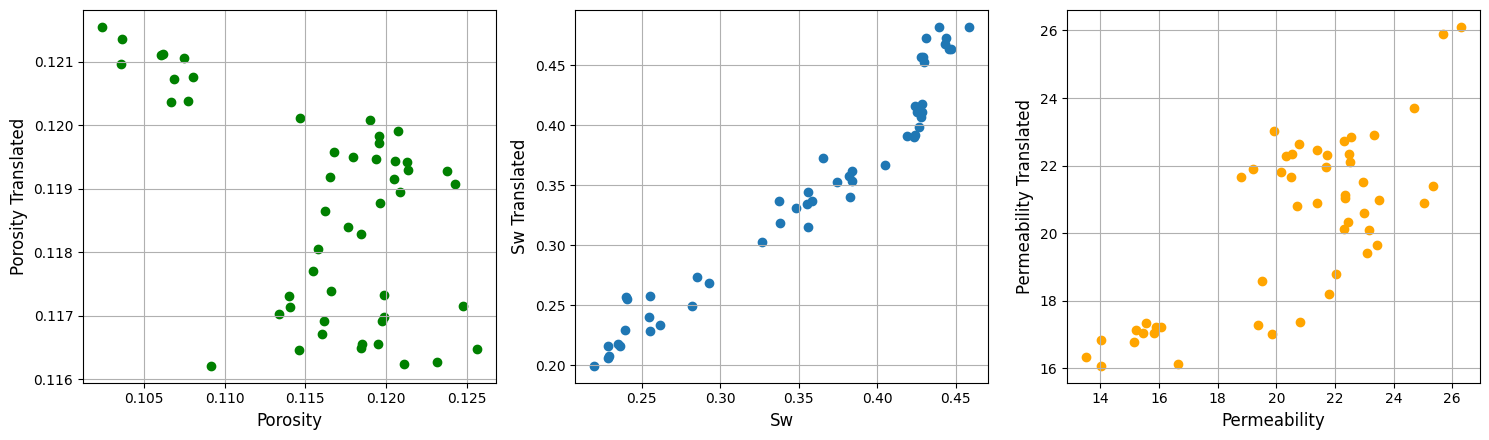

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))  # 1 row, 3 columns

# Plot 1: Porosity
axes[0].scatter(params_test_avg[:, 0], simu_in_recons_inversed[:, 0], color = 'g')
axes[0].set_xlabel('Porosity', fontsize = 12)
axes[0].set_ylabel('Porosity Translated', fontsize = 12)
axes[0].grid()

# Plot 2: Sw
axes[1].scatter(params_test_avg[:, 1], simu_in_recons_inversed[:, 1])
axes[1].set_xlabel('Sw', fontsize = 12)
axes[1].set_ylabel('Sw Translated', fontsize = 12)
axes[1].grid()

# Plot 3: Permeability
axes[2].scatter(params_test_avg[:, 2], simu_in_recons_inversed[:, 2],  color = 'orange')
axes[2].set_xlabel('Permeability', fontsize = 12)
axes[2].set_ylabel('Permeability Translated', fontsize = 12)  # Added for consistency
axes[2].grid()

plt.tight_layout()
plt.show()


## GA

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings("ignore", message="X does not have valid feature names")

def evaluate_fitness_recons(simu_in_recons_candidate, x2_fixed, y_target, proxy, assemble_fn):
    # simu_in_recons_candidate: shape (1, 3)
    # x2_fixed: shape (1, 73, 5)
    simu_input = assemble_fn(tf.cast(simu_in_recons_candidate, tf.float32),
                             tf.cast(x2_fixed, tf.float32))  # → (1, 73, 8)
    proxy_out = proxy.predict(simu_input, verbose=0)  # → (1, 73, 1)
    mse = mean_squared_error(y_target.reshape(-1), proxy_out.reshape(-1))
    return mse

def genetic_algorithm_recons(y_target, x2_fixed, proxy, assemble_fn,
                             bounds=[(0.1, 0.15), (0.2, 0.5), (10, 30)],
                             pop_size=30, n_gen=50, mutation_rate=0.1):
    dim = len(bounds)  # = 3
    population = np.random.uniform(
        low=[b[0] for b in bounds],
        high=[b[1] for b in bounds],
        size=(pop_size, dim)
    )  # shape: (pop_size, 3)

    for gen in range(n_gen):
        fitness = []
        for i in range(pop_size):
            candidate = population[i:i+1]  # shape: (1, 3)
            candidate_scaled = vae_scaler.transform(candidate)  # shape: (1, 3)

            loss = evaluate_fitness_recons(candidate_scaled, x2_fixed, y_target, proxy, assemble_fn)
            fitness.append(loss)

        fitness = np.array(fitness)
        elite_count = max(1, pop_size // 5)
        elite_indices = np.argsort(fitness)[:elite_count]
        elites = population[elite_indices]

        # Crossover
        children = []
        while len(children) < pop_size - elite_count:
            p1, p2 = elites[np.random.choice(elite_count, 2, replace=False)]
            alpha = np.random.rand()
            child = alpha * p1 + (1 - alpha) * p2
            children.append(child)
        children = np.array(children)

        # Mutation
        mutation_mask = np.random.rand(*children.shape) < mutation_rate
        # ranges = np.array([high - low for (low, high) in bounds])
        noise = np.random.normal(0, 0.02, size=children.shape)
        children += mutation_mask * noise

        # Clip to bounds
        for j in range(dim):
            low, high = bounds[j]
            children[:, j] = np.clip(children[:, j], low, high)

        population = np.vstack([elites, children])
        print(f"Gen {gen+1}/{n_gen} — Best MSE: {fitness.min():.6f}")

    best_idx = np.argmin(fitness)
    best_recons = population[best_idx]  # shape: (3,)
    return best_recons, fitness[best_idx]

In [ ]:
def optimize_all_samples(assim_x2_scaled_test, assim_y_scaled_test,
                         proxy, assemble_fn,
                         bounds=[(0.1, 0.15), (0.2, 0.5), (10, 30)]):

    best_inputs = []
    for i in range(len(assim_y_scaled_test)):
        print(f"\n🔍 Optimizing sample {i+1}/{len(assim_y_scaled_test)}")
        best_recons, best_loss = genetic_algorithm_recons(
            y_target=assim_y_scaled_test[i],
            x2_fixed=assim_x2_scaled_test[i:i+1],
            proxy=proxy,
            assemble_fn=assemble_simu_in,
            bounds=bounds,
            pop_size=30,
            n_gen=50
        )
        best_inputs.append(best_recons)

    return np.array(best_inputs)  # shape: (N, 3)


In [ ]:
optimized_vectors = optimize_all_samples(
    assim_x2_scaled_test=assim_x2_scaled_test,
    assim_y_scaled_test=assim_y_scaled_test,
    proxy=proxy,
    assemble_fn=assemble_simu_in
)

print("✅ Optimization completed.")
print("Optimized simu_in_recons shape:", optimized_vectors.shape)  # → (N, 3)

Gen 22/50 — Best MSE: 0.003909
Gen 23/50 — Best MSE: 0.003909
Gen 24/50 — Best MSE: 0.003905
Gen 25/50 — Best MSE: 0.003905
Gen 26/50 — Best MSE: 0.003905
Gen 27/50 — Best MSE: 0.003905
Gen 28/50 — Best MSE: 0.003905
Gen 29/50 — Best MSE: 0.003905
Gen 30/50 — Best MSE: 0.003905
Gen 31/50 — Best MSE: 0.003905
Gen 32/50 — Best MSE: 0.003905
Gen 33/50 — Best MSE: 0.003905
Gen 34/50 — Best MSE: 0.003905
Gen 35/50 — Best MSE: 0.003905
Gen 36/50 — Best MSE: 0.003905
Gen 37/50 — Best MSE: 0.003905
Gen 38/50 — Best MSE: 0.003905
Gen 39/50 — Best MSE: 0.003905
Gen 40/50 — Best MSE: 0.003905
Gen 41/50 — Best MSE: 0.003905
Gen 42/50 — Best MSE: 0.003905
Gen 43/50 — Best MSE: 0.003898
Gen 44/50 — Best MSE: 0.003898
Gen 45/50 — Best MSE: 0.003897
Gen 46/50 — Best MSE: 0.003894
Gen 47/50 — Best MSE: 0.003891
Gen 48/50 — Best MSE: 0.003891
Gen 49/50 — Best MSE: 0.003891
Gen 50/50 — Best MSE: 0.003891

🔍 Optimizing sample 27/50
Gen 1/50 — Best MSE: 0.026298
Gen 2/50 — Best MSE: 0.004522
Gen 3/50 — Bes

In [ ]:
import pickle

# Save the optimized vectors to a .pkl file
with open("GA history matching/optimized_simu_in_recons.pkl", "wb") as f:
    pickle.dump(optimized_vectors, f)

print("✅ Results saved to optimized_simu_in_recons.pkl")

✅ Results saved to optimized_simu_in_recons.pkl


In [ ]:
import pickle

with open("GA history matching/optimized_simu_in_recons.pkl", "rb") as f:
    optimized_vectors = pickle.load(f)

print("Loaded optimized vectors with shape:", optimized_vectors.shape)

Loaded optimized vectors with shape: (50, 3)


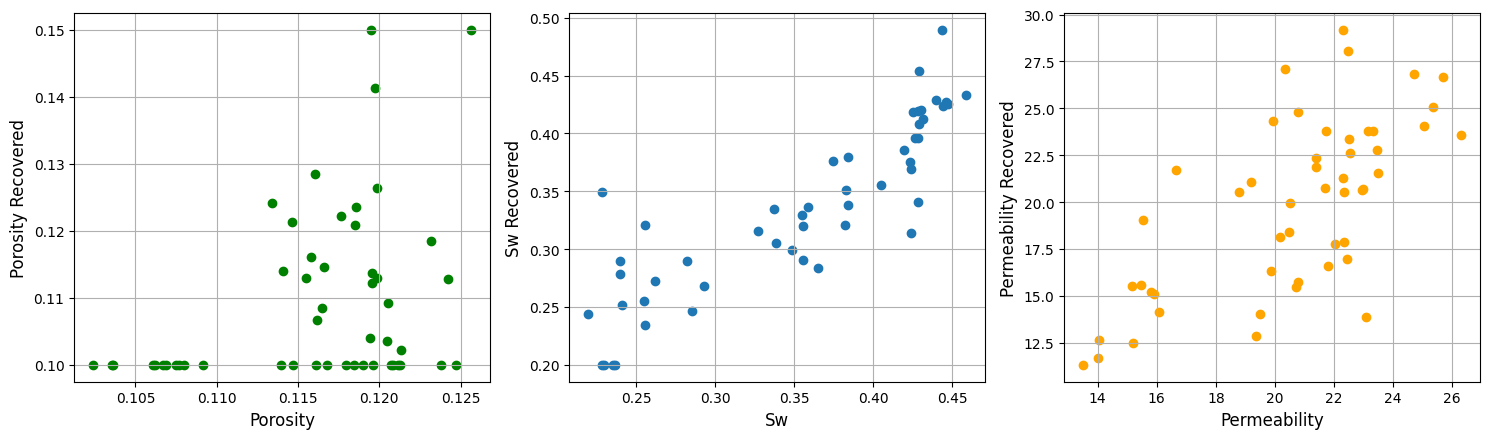

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))  # 1 row, 3 columns

# Plot 1: Porosity
axes[0].scatter(params_test_avg[:, 0], optimized_vectors[:, 0], color = 'g')
axes[0].set_xlabel('Porosity', fontsize = 12)
axes[0].set_ylabel('Porosity Recovered', fontsize = 12)
axes[0].grid()

# Plot 2: Sw
axes[1].scatter(params_test_avg[:, 1], optimized_vectors[:, 1])
axes[1].set_xlabel('Sw', fontsize = 12)
axes[1].set_ylabel('Sw Recovered', fontsize = 12)
axes[1].grid()

# Plot 3: Permeability
axes[2].scatter(params_test_avg[:, 2], optimized_vectors[:, 2],  color = 'orange')
axes[2].set_xlabel('Permeability', fontsize = 12)
axes[2].set_ylabel('Permeability Recovered', fontsize = 12)  # Added for consistency
axes[2].grid()

plt.tight_layout()
plt.show()